# Lab Sheet-I

## Q1. Euler

$y'=y-x^2+1$, $y(0)=0.5$, $h=0.1$

       x         Euler         Exact         Error
    0.00      0.500000      0.500000      0.000000
    0.10      0.650000      0.657415      0.007415
    0.20      0.814000      0.829299      0.015299
    0.30      0.991400      1.015071      0.023671
    0.40      1.181540      1.214088      0.032548
    0.50      1.383694      1.425639      0.041945
    0.60      1.597063      1.648941      0.051877
    0.70      1.820770      1.883124      0.062354
    0.80      2.053847      2.127230      0.073383
    0.90      2.295231      2.380198      0.084967
    1.00      2.543755      2.640859      0.097105


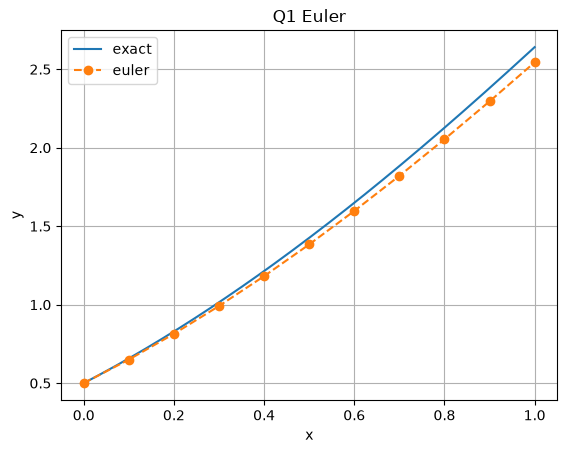

In [14]:
import numpy as np
import matplotlib.pyplot as plt

h = 0.1
n = 10   # from 0 to 1

x = 0.0
y = 0.5
X = [x]
Y = [y]

for i in range(n):
    f = y - x*x + 1
    y = y + h*f      # euler step
    x = x + h
    X.append(x)
    Y.append(y)

print(f"{'x':>8}  {'Euler':>12}  {'Exact':>12}  {'Error':>12}")
for i in range(len(X)):
    exact = (X[i]+1)**2 - 0.5*np.exp(X[i])
    print(f"{X[i]:8.2f}  {Y[i]:12.6f}  {exact:12.6f}  {abs(Y[i]-exact):12.6f}")

xx = np.linspace(0, 1, 200)
yy = (xx+1)**2 - 0.5*np.exp(xx)

plt.plot(xx, yy, label="exact")
plt.plot(X, Y, "o--", label="euler")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q1 Euler")
plt.legend()
plt.grid()
plt.show()

# error keeps increasing with x

## Q2. Backward Euler

$y'=-50y$, $y(0)=1$, $h=0.1$  
got $y_{n+1}=y_n/(1+50h)$

       x       bwd euler       fwd euler           exact
    0.00        1.000000            1.00        1.000000
    0.10        0.166667           -4.00        0.006738
    0.20        0.027778           16.00        0.000045
    0.30        0.004630          -64.00        0.000000
    0.40        0.000772          256.00        0.000000
    0.50        0.000129        -1024.00        0.000000
    0.60        0.000021         4096.00        0.000000
    0.70        0.000004       -16384.00        0.000000
    0.80        0.000001        65536.00        0.000000
    0.90        0.000000      -262144.00        0.000000
    1.00        0.000000      1048576.00        0.000000


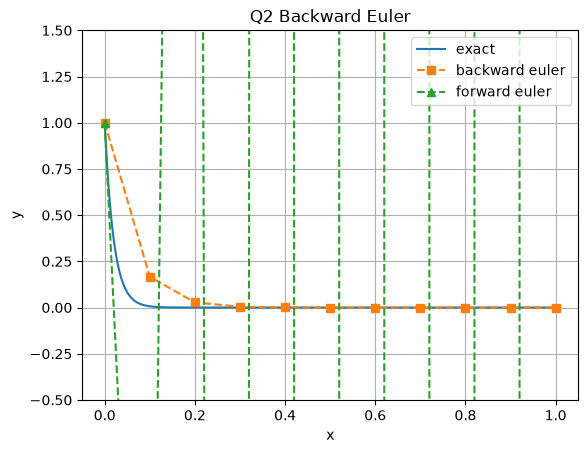

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

h = 0.1
n = 10

# backward euler
x = 0.0
y = 1.0
X = [x]
Yb = [y]

for i in range(n):
    y = y / (1 + 50*h) 
    x = x + h
    X.append(x)
    Yb.append(y)

# forward euler for comparison (blows up)
x = 0.0
y = 1.0
Yf = [y]

for i in range(n):
    y = y + h*(-50*y)
    x = x + h
    Yf.append(y)

print(f"{'x':>8}  {'bwd euler':>14}  {'fwd euler':>14}  {'exact':>14}")
for i in range(len(X)):
    exact = np.exp(-50*X[i])
    print(f"{X[i]:8.2f}  {Yb[i]:14.6f}  {Yf[i]:14.2f}  {exact:14.6f}")

xx = np.linspace(0, 1, 400)
plt.plot(xx, np.exp(-50*xx), label="exact")
plt.plot(X, Yb, "s--", label="backward euler")
plt.plot(X, Yf, "^--", label="forward euler")
plt.ylim(-0.5, 1.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q2 Backward Euler")
plt.legend()
plt.grid()
plt.show()

# fwd euler unstable, bwd euler ok

## Q3. Improved Euler

$y'=x+y$, $y(0)=1$, $h=0.1$

       x          Heun         Euler         Exact
    0.00      1.000000      1.000000      1.000000
    0.10      1.110000      1.100000      1.110342
    0.20      1.242050      1.220000      1.242806
    0.30      1.398465      1.362000      1.399718
    0.40      1.581804      1.528200      1.583649
    0.50      1.794894      1.721020      1.797443
    0.60      2.040857      1.943122      2.044238
    0.70      2.323147      2.197434      2.327505
    0.80      2.645578      2.487178      2.651082
    0.90      3.012364      2.815895      3.019206
    1.00      3.428162      3.187485      3.436564


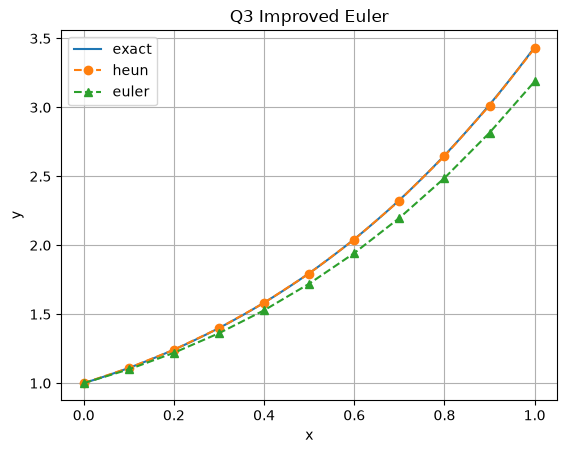

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

h = 0.1
n = 10

# heun
x = 0.0
y = 1.0
X = [x]
Yh = [y]

for i in range(n):
    f1 = x + y
    y_pred = y + h*f1      
    f2 = (x+h) + y_pred
    y = y + (h/2)*(f1 + f2)  
    x = x + h
    X.append(x)
    Yh.append(y)

# normal euler also
x = 0.0
y = 1.0
Ye = [y]

for i in range(n):
    y = y + h*(x + y)
    x = x + h
    Ye.append(y)

print(f"{'x':>8}  {'Heun':>12}  {'Euler':>12}  {'Exact':>12}")
for i in range(len(X)):
    exact = 2*np.exp(X[i]) - X[i] - 1
    print(f"{X[i]:8.2f}  {Yh[i]:12.6f}  {Ye[i]:12.6f}  {exact:12.6f}")

xx = np.linspace(0, 1, 200)
plt.plot(xx, 2*np.exp(xx)-xx-1, label="exact")
plt.plot(X, Yh, "o--", label="heun")
plt.plot(X, Ye, "^--", label="euler")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q3 Improved Euler")
plt.legend()
plt.grid()
plt.show()

# heun better than euler

## Q4. Modified Euler (midpoint)

$y'=xy$, $y(0)=1$, $h=0.1$ and $0.05$

--- h = 0.1 ---
       x     Mod Euler         Exact         Error
    0.00      1.000000      1.000000      0.000000
    0.10      1.005000      1.005013      0.000013
    0.20      1.020150      1.020201      0.000051
    0.30      1.045909      1.046028      0.000119
    0.40      1.083065      1.083287      0.000222
    0.50      1.132778      1.133148      0.000371
    0.60      1.196638      1.197217      0.000579
    0.70      1.276753      1.277621      0.000868
    0.80      1.375861      1.377128      0.001267
    0.90      1.497487      1.499303      0.001815
    1.00      1.646150      1.648721      0.002571

--- h = 0.05 ---
       x     Mod Euler         Exact         Error
    0.00      1.000000      1.000000      0.000000
    0.05      1.001250      1.001251      0.000001
    0.10      1.005009      1.005013      0.000003
    0.15      1.011306      1.011314      0.000007
    0.20      1.020189      1.020201      0.000013
    0.25      1.031723      1.031743      0.0000

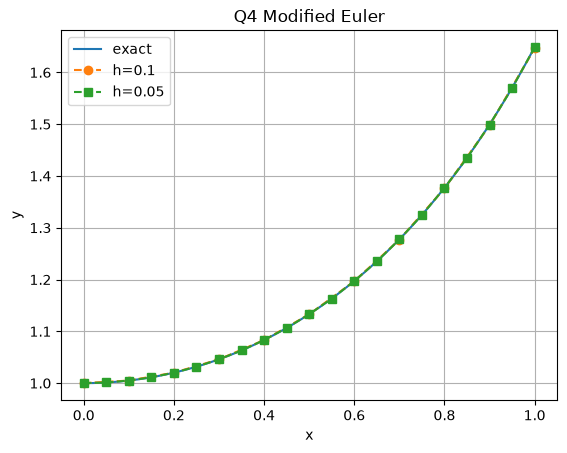

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def run_midpoint(h):
    n = int(round(1/h))
    x = 0.0
    y = 1.0
    X = [x]
    Y = [y]
    for i in range(n):
        ym = y + (h/2)*(x*y)           # midpoint value
        y = y + h*((x + h/2)*ym)       # full step using mid slope
        x = x + h
        X.append(x)
        Y.append(y)
    return X, Y

X1, Y1 = run_midpoint(0.1)
X2, Y2 = run_midpoint(0.05)

print("--- h = 0.1 ---")
print(f"{'x':>8}  {'Mod Euler':>12}  {'Exact':>12}  {'Error':>12}")
for i in range(len(X1)):
    exact = np.exp(X1[i]**2 / 2)
    print(f"{X1[i]:8.2f}  {Y1[i]:12.6f}  {exact:12.6f}  {abs(Y1[i]-exact):12.6f}")

print("\n--- h = 0.05 ---")
print(f"{'x':>8}  {'Mod Euler':>12}  {'Exact':>12}  {'Error':>12}")
for i in range(len(X2)):
    exact = np.exp(X2[i]**2 / 2)
    print(f"{X2[i]:8.2f}  {Y2[i]:12.6f}  {exact:12.6f}  {abs(Y2[i]-exact):12.6f}")

e1 = abs(Y1[-1] - np.exp(0.5))
e2 = abs(Y2[-1] - np.exp(0.5))
print(f"\nerror at x=1: {e1:.6f}, {e2:.6f}")
print(f"ratio: {e1/e2:.2f}")   # ~4 means order 2

xx = np.linspace(0, 1, 200)
plt.plot(xx, np.exp(xx**2/2), label="exact")
plt.plot(X1, Y1, "o--", label="h=0.1")
plt.plot(X2, Y2, "s--", label="h=0.05")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q4 Modified Euler")
plt.legend()
plt.grid()
plt.show()

## Q5. RK4

$y'=\cos x-y$, $y(0)=1$, $h=0.2$, till $x=2$

       x           RK4         Exact         Error
    0.00      1.000000      1.000000      0.000000
    0.20      0.998733      0.998733      0.000001
    0.40      0.990398      0.990400      0.000001
    0.60      0.969392      0.969395      0.000002
    0.80      0.931693      0.931696      0.000003
    1.00      0.874822      0.874826      0.000004
    1.20      0.797791      0.797796      0.000005
    1.40      0.701002      0.701007      0.000005
    1.60      0.586131      0.586135      0.000005
    1.80      0.455968      0.455972      0.000004
    2.00      0.314239      0.314243      0.000004


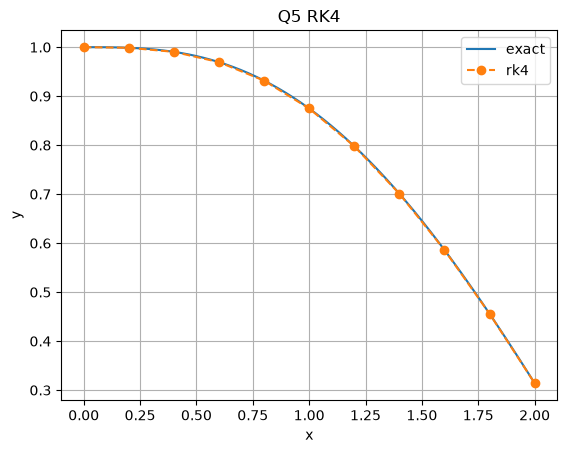

In [18]:
import numpy as np
import matplotlib.pyplot as plt

h = 0.2
n = 10   # 0 to 2

x = 0.0
y = 1.0
X = [x]
Y = [y]

for i in range(n):
    k1 = np.cos(x) - y
    k2 = np.cos(x + h/2) - (y + h*k1/2)
    k3 = np.cos(x + h/2) - (y + h*k2/2)
    k4 = np.cos(x + h) - (y + h*k3)

    y = y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    x = x + h
    X.append(x)
    Y.append(y)

print(f"{'x':>8}  {'RK4':>12}  {'Exact':>12}  {'Error':>12}")
for i in range(len(X)):
    exact = 0.5*(np.sin(X[i]) + np.cos(X[i])) + 0.5*np.exp(-X[i])
    print(f"{X[i]:8.2f}  {Y[i]:12.6f}  {exact:12.6f}  {abs(Y[i]-exact):12.6f}")

xx = np.linspace(0, 2, 300)
yy = 0.5*(np.sin(xx)+np.cos(xx)) + 0.5*np.exp(-xx)

plt.plot(xx, yy, label="exact")
plt.plot(X, Y, "o--", label="rk4")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q5 RK4")
plt.legend()
plt.grid()
plt.show()

# errors are tiny

## Q6. Compare all

$y'=y(1-y)$, $y(0)=0.5$, $h=0.25$ and $0.125$

h = 0.25
       x       euler         bwd        heun         mid         rk4       exact
   0.000    0.500000    0.500000    0.500000    0.500000    0.500000    0.500000
   0.250    0.562500    0.561553    0.562012    0.562256    0.562176    0.562177
   0.500    0.624023    0.620427    0.622123    0.622593    0.622459    0.622459
   0.750    0.682678    0.675249    0.678668    0.679319    0.679178    0.679179
   1.000    0.736835    0.725083    0.730381    0.731154    0.731058    0.731059



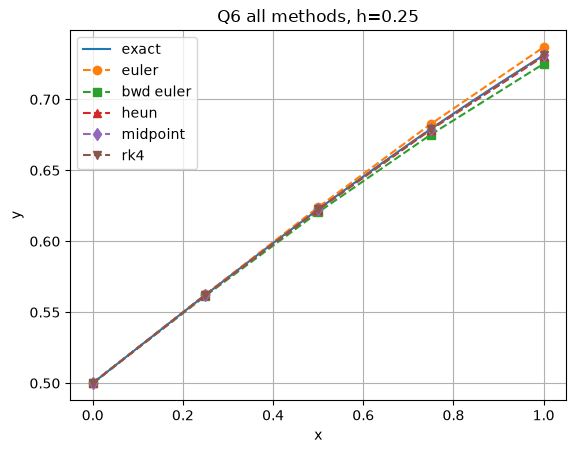

h = 0.125
       x       euler         bwd        heun         mid         rk4       exact
   0.000    0.500000    0.500000    0.500000    0.500000    0.500000    0.500000
   0.125    0.531250    0.531129    0.531189    0.531219    0.531209    0.531209
   0.250    0.562378    0.561900    0.562135    0.562196    0.562176    0.562177
   0.375    0.593142    0.592090    0.592605    0.592694    0.592667    0.592667
   0.500    0.623307    0.621495    0.622377    0.622491    0.622459    0.622459
   0.625    0.652657    0.649935    0.651251    0.651389    0.651355    0.651355
   0.750    0.680994    0.677257    0.679054    0.679212    0.679179    0.679179
   0.875    0.708149    0.703339    0.705641    0.705814    0.705785    0.705785
   1.000    0.733983    0.728086    0.730895    0.731080    0.731059    0.731059



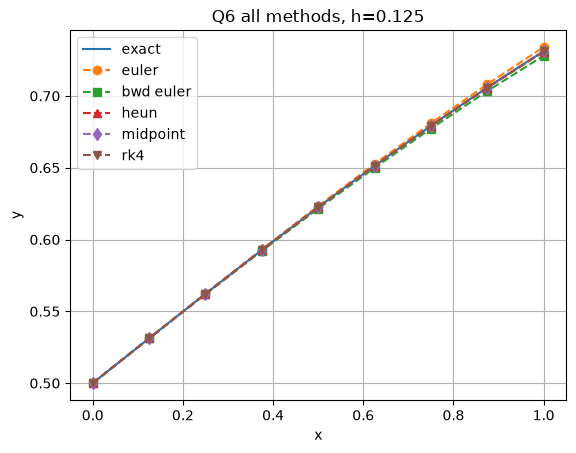

In [19]:
import numpy as np
import matplotlib.pyplot as plt

def all_methods(h):
    n = int(round(1/h))
    x = [0.0]

    ye = [0.5]   # euler
    yb = [0.5]   # bwd euler
    yh = [0.5]   # heun
    ym = [0.5]   # midpoint
    yr = [0.5]   # rk4

    for i in range(n):
        # euler
        ye.append(ye[-1] + h*ye[-1]*(1-ye[-1]))

        # bwd euler (solve quadratic)
        yn = yb[-1]
        yb.append((-(1-h) + np.sqrt((1-h)**2 + 4*h*yn))/(2*h))

        # heun
        f1 = yh[-1]*(1-yh[-1])
        yp = yh[-1] + h*f1
        f2 = yp*(1-yp)
        yh.append(yh[-1] + (h/2)*(f1+f2))

        # midpoint
        f1 = ym[-1]*(1-ym[-1])
        ymid = ym[-1] + (h/2)*f1
        ym.append(ym[-1] + h*ymid*(1-ymid))

        # rk4
        y0 = yr[-1]
        k1 = y0*(1-y0)
        k2 = (y0 + h*k1/2)*(1 - (y0 + h*k1/2))
        k3 = (y0 + h*k2/2)*(1 - (y0 + h*k2/2))
        k4 = (y0 + h*k3)*(1 - (y0 + h*k3))
        yr.append(y0 + (h/6)*(k1 + 2*k2 + 2*k3 + k4))

        x.append(x[-1] + h)

    return x, ye, yb, yh, ym, yr

for h in [0.25, 0.125]:
    x, ye, yb, yh, ym, yr = all_methods(h)

    print("h =", h)
    print(f"{'x':>8}  {'euler':>10}  {'bwd':>10}  {'heun':>10}  {'mid':>10}  {'rk4':>10}  {'exact':>10}")
    for i in range(len(x)):
        exact = 1/(1 + np.exp(-x[i]))
        print(f"{x[i]:8.3f}  {ye[i]:10.6f}  {yb[i]:10.6f}  {yh[i]:10.6f}  {ym[i]:10.6f}  {yr[i]:10.6f}  {exact:10.6f}")
    print()

    xx = np.linspace(0, 1, 200)
    plt.figure()
    plt.plot(xx, 1/(1+np.exp(-xx)), label="exact")
    plt.plot(x, ye, "o--", label="euler")
    plt.plot(x, yb, "s--", label="bwd euler")
    plt.plot(x, yh, "^--", label="heun")
    plt.plot(x, ym, "d--", label="midpoint")
    plt.plot(x, yr, "v--", label="rk4")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Q6 all methods, h=" + str(h))
    plt.legend()
    plt.grid()
    plt.show()